# Telecom Plan Revenue Analysis: Surf vs. Ultimate

Megaline, a telecom operator, offers its customers two prepaid plans: **Surf** and **Ultimate**. The commercial department wants to know which plan generates more revenue in order to adjust the advertising budget.

This notebook performs a preliminary analysis on a sample of 500 Megaline customers: who they are, where they are from, which plan they use, and the calls, text messages and mobile data sessions they used in 2018. The goal is to analyze customer behavior and determine which prepaid plan generates more revenue.

## Approach

1. Load and inspect the five source tables (plans, users, calls, messages and internet sessions).
2. Correct data types and enrich the tables where useful.
3. Aggregate usage per user and per month.
4. Calculate the monthly revenue of each user according to the rules of their plan.
5. Compare usage and revenue between plans using descriptive statistics and charts.
6. Test two statistical hypotheses about average revenue.

## Setup

In [99]:
# Load libraries
from scipy import stats as st
import numpy as np
import pandas as pd
import math as mt
from matplotlib import pyplot as plt
import seaborn as sns

## Load Data

In [2]:
# Load each data file into its own DataFrame
df_calls = pd.read_csv("datasets/megaline_calls.csv")
df_internet = pd.read_csv("datasets/megaline_internet.csv")
df_messages = pd.read_csv("datasets/megaline_messages.csv")
df_plans = pd.read_csv("datasets/megaline_plans.csv")
df_users = pd.read_csv("datasets/megaline_users.csv")

## Data Preparation

The data is split across five tables. Each table is explored individually and corrected where necessary before the usage data is aggregated.

### Plans

In [3]:
# General information about the plans DataFrame
df_plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 260.0+ bytes


In [4]:
# Plans data
df_plans

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


The plans table has two rows (one per plan), no missing values and appropriate data types. Note that the data allowance is expressed in megabytes (`mb_per_month_included`), while data overage is charged per gigabyte (`usd_per_gb`).

#### Data Corrections

No corrections are required for the plans table.

#### Data Enrichment

`plan_name` is renamed to `plan` so that it matches the corresponding column in the users table and can be used as a join key.

In [6]:
df_plans.rename(columns = {'plan_name' : 'plan'}, inplace = True)
df_plans

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


### Users

In [7]:
# General information about the users DataFrame
df_users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


In [8]:
# Sample of the users data
df_users.sample(10, random_state=1)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
304,1304,Dominque,Cole,69,"Birmingham-Hoover, AL MSA",2018-10-28,ultimate,NaN
340,1340,Vanna,Stanton,65,"Dallas-Fort Worth-Arlington, TX MSA",2018-07-05,surf,NaN
47,1047,Yuk,French,22,"Indianapolis-Carmel-Anderson, IN MSA",2018-06-16,ultimate,NaN
67,1067,Robt,Allen,37,"Grand Rapids-Kentwood, MI MSA",2018-09-24,surf,2018-11-24
479,1479,Keesha,Burnett,44,"Riverside-San Bernardino-Ontario, CA MSA",2018-11-12,surf,NaN
485,1485,Damion,Woodard,67,"Nashville-Davidson–Murfreesboro–Franklin, TN MSA",2018-08-21,surf,NaN
310,1310,Vincent,Fry,73,"Portland-Vancouver-Hillsboro, OR-WA MSA",2018-11-29,surf,NaN
31,1031,Lane,Martin,52,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-07-15,ultimate,NaN
249,1249,Kelly,Goodman,41,"Cincinnati, OH-KY-IN MSA",2018-05-14,ultimate,NaN
90,1090,Brock,Skinner,30,"Indianapolis-Carmel-Anderson, IN MSA",2018-05-12,surf,NaN


The only missing values are in `churn_date` (34 non-null values out of 500). This is expected: a missing churn date means the customer had not cancelled the plan when the data was extracted. The date columns (`reg_date` and `churn_date`) are stored as strings and need to be converted to `datetime`.

#### Data Corrections

The date columns are converted to `datetime`, and first and last names are normalized to lowercase.

In [9]:
df_users["reg_date"] = pd.to_datetime(df_users["reg_date"])
df_users["churn_date"] = pd.to_datetime(df_users["churn_date"])
df_users["first_name"] = df_users["first_name"].str.lower()
df_users["last_name"] = df_users["last_name"].str.lower()
df_users.info()
df_users.sample(10, random_state=1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    object        
 2   last_name   500 non-null    object        
 3   age         500 non-null    int64         
 4   city        500 non-null    object        
 5   reg_date    500 non-null    datetime64[ns]
 6   plan        500 non-null    object        
 7   churn_date  34 non-null     datetime64[ns]
dtypes: datetime64[ns](2), int64(2), object(4)
memory usage: 31.4+ KB


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
304,1304,dominque,cole,69,"Birmingham-Hoover, AL MSA",2018-10-28,ultimate,NaT
340,1340,vanna,stanton,65,"Dallas-Fort Worth-Arlington, TX MSA",2018-07-05,surf,NaT
47,1047,yuk,french,22,"Indianapolis-Carmel-Anderson, IN MSA",2018-06-16,ultimate,NaT
67,1067,robt,allen,37,"Grand Rapids-Kentwood, MI MSA",2018-09-24,surf,2018-11-24
479,1479,keesha,burnett,44,"Riverside-San Bernardino-Ontario, CA MSA",2018-11-12,surf,NaT
485,1485,damion,woodard,67,"Nashville-Davidson–Murfreesboro–Franklin, TN MSA",2018-08-21,surf,NaT
310,1310,vincent,fry,73,"Portland-Vancouver-Hillsboro, OR-WA MSA",2018-11-29,surf,NaT
31,1031,lane,martin,52,"New York-Newark-Jersey City, NY-NJ-PA MSA",2018-07-15,ultimate,NaT
249,1249,kelly,goodman,41,"Cincinnati, OH-KY-IN MSA",2018-05-14,ultimate,NaT
90,1090,brock,skinner,30,"Indianapolis-Carmel-Anderson, IN MSA",2018-05-12,surf,NaT


### Calls

In [10]:
# General information about the calls DataFrame
df_calls.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB


In [11]:
# Sample of the calls data
df_calls.sample(10, random_state=1)


,id,user_id,call_date,duration
106231,1374_327,1374,2018-12-17,1.17
109017,1385_87,1385,2018-10-20,14.02
76096,1268_600,1268,2018-09-24,12.21
106317,1375_219,1375,2018-12-03,7.03
98706,1354_6,1354,2018-10-16,6.21
50517,1182_90,1182,2018-11-18,1.96
13355,1057_234,1057,2018-10-03,0.00
50255,1181_604,1181,2018-12-28,11.65
129376,1465_773,1465,2018-07-27,12.75
51887,1187_80,1187,2018-12-22,14.22


The calls table has no missing values. `call_date` is stored as a string and needs to be converted to `datetime`. The sample also shows calls with a duration of 0.00 minutes.

#### Data Corrections

In [12]:
df_calls["call_date"] = pd.to_datetime(df_calls["call_date"])
df_calls.sample(10, random_state=1)

,id,user_id,call_date,duration
106231,1374_327,1374,2018-12-17,1.17
109017,1385_87,1385,2018-10-20,14.02
76096,1268_600,1268,2018-09-24,12.21
106317,1375_219,1375,2018-12-03,7.03
98706,1354_6,1354,2018-10-16,6.21
50517,1182_90,1182,2018-11-18,1.96
13355,1057_234,1057,2018-10-03,0.00
50255,1181_604,1181,2018-12-28,11.65
129376,1465_773,1465,2018-07-27,12.75
51887,1187_80,1187,2018-12-22,14.22


#### Data Enrichment

Customer names are added from the users table.

In [13]:
df_calls = df_calls.merge(df_users[["user_id","first_name", "last_name"]], on="user_id", how="left")
df_calls.sample(10, random_state=1)

,id,user_id,call_date,duration,first_name,last_name
106231,1374_327,1374,2018-12-17,1.17,ching,watts
109017,1385_87,1385,2018-10-20,14.02,nohemi,erickson
76096,1268_600,1268,2018-09-24,12.21,britni,bowers
106317,1375_219,1375,2018-12-03,7.03,andy,holden
98706,1354_6,1354,2018-10-16,6.21,leonel,dyer
50517,1182_90,1182,2018-11-18,1.96,jeff,burt
13355,1057_234,1057,2018-10-03,0.00,theo,sargent
50255,1181_604,1181,2018-12-28,11.65,ron,kaufman
129376,1465_773,1465,2018-07-27,12.75,arianna,morrison
51887,1187_80,1187,2018-12-22,14.22,tanner,goodman


### Messages

In [14]:
# General information about the messages DataFrame
df_messages.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


In [15]:
# Sample of the messages data
df_messages.sample(10, random_state=1)


,id,user_id,message_date
12922,1084_162,1084,2018-11-17
55949,1354_99,1354,2018-10-04
19111,1123_180,1123,2018-11-04
46123,1314_11,1314,2018-12-15
72141,1467_473,1467,2018-05-18
58237,1369_38,1369,2018-12-15
55621,1349_433,1349,2018-10-11
18826,1122_55,1122,2018-07-13
64105,1408_230,1408,2018-06-05
6990,1057_314,1057,2018-11-18


The messages table has no missing values. `message_date` is stored as a string and needs to be converted to `datetime`.

#### Data Corrections

In [16]:
df_messages["message_date"] = pd.to_datetime(df_messages["message_date"])
df_messages.info()
df_messages.sample(10, random_state=1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB


,id,user_id,message_date
12922,1084_162,1084,2018-11-17
55949,1354_99,1354,2018-10-04
19111,1123_180,1123,2018-11-04
46123,1314_11,1314,2018-12-15
72141,1467_473,1467,2018-05-18
58237,1369_38,1369,2018-12-15
55621,1349_433,1349,2018-10-11
18826,1122_55,1122,2018-07-13
64105,1408_230,1408,2018-06-05
6990,1057_314,1057,2018-11-18


#### Data Enrichment

Customer names are added from the users table.

In [17]:
df_messages = df_messages.merge(df_users[["user_id","first_name", "last_name"]], on="user_id", how="left")
df_messages.sample(10, random_state=1)

,id,user_id,message_date,first_name,last_name
12922,1084_162,1084,2018-11-17,wiley,mckinney
55949,1354_99,1354,2018-10-04,leonel,dyer
19111,1123_180,1123,2018-11-04,dierdre,nash
46123,1314_11,1314,2018-12-15,brice,morgan
72141,1467_473,1467,2018-05-18,nickolas,deleon
58237,1369_38,1369,2018-12-15,bernard,mckee
55621,1349_433,1349,2018-10-11,florentina,diaz
18826,1122_55,1122,2018-07-13,lashay,reese
64105,1408_230,1408,2018-06-05,alaine,robertson
6990,1057_314,1057,2018-11-18,theo,sargent


### Internet

In [18]:
# General information about the internet DataFrame
df_internet.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


In [19]:
# Sample of the internet usage data
df_internet.sample(10, random_state=1)


,id,user_id,session_date,mb_used
13106,1062_76,1062,2018-09-15,225.79
70950,1331_201,1331,2018-09-28,169.69
6195,1035_43,1035,2018-12-27,124.84
2400,1011_140,1011,2018-06-26,0.00
25926,1121_19,1121,2018-12-16,504.92
63187,1291_312,1291,2018-07-08,289.98
16908,1077_28,1077,2018-12-12,465.72
64323,1295_223,1295,2018-12-20,549.30
95470,1445_118,1445,2018-08-13,405.50
55326,1251_137,1251,2018-12-18,285.50


The internet sessions table has no missing values. `session_date` is stored as a string and needs to be converted to `datetime`. The sample also shows sessions with 0.00 MB used.

#### Data Corrections

In [20]:
df_internet["session_date"] = pd.to_datetime(df_internet["session_date"])
df_internet.info()
df_internet.sample(10, random_state=1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  object        
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 3.2+ MB


,id,user_id,session_date,mb_used
13106,1062_76,1062,2018-09-15,225.79
70950,1331_201,1331,2018-09-28,169.69
6195,1035_43,1035,2018-12-27,124.84
2400,1011_140,1011,2018-06-26,0.00
25926,1121_19,1121,2018-12-16,504.92
63187,1291_312,1291,2018-07-08,289.98
16908,1077_28,1077,2018-12-12,465.72
64323,1295_223,1295,2018-12-20,549.30
95470,1445_118,1445,2018-08-13,405.50
55326,1251_137,1251,2018-12-18,285.50


#### Data Enrichment

Customer names are added from the users table.

In [21]:
df_internet = df_internet.merge(df_users[["user_id","first_name", "last_name"]], on="user_id", how="left")
df_internet.sample(10, random_state=1)

,id,user_id,session_date,mb_used,first_name,last_name
13106,1062_76,1062,2018-09-15,225.79,kristeen,head
70950,1331_201,1331,2018-09-28,169.69,lashandra,ramos
6195,1035_43,1035,2018-12-27,124.84,jeff,cummings
2400,1011_140,1011,2018-06-26,0.00,halina,henry
25926,1121_19,1121,2018-12-16,504.92,kathaleen,albert
63187,1291_312,1291,2018-07-08,289.98,angeles,mejia
16908,1077_28,1077,2018-12-12,465.72,chau,webster
64323,1295_223,1295,2018-12-20,549.30,hung,flowers
95470,1445_118,1445,2018-08-13,405.50,elodia,donovan
55326,1251_137,1251,2018-12-18,285.50,tifany,mcgee


## Plan Conditions

Understanding how customers are charged is essential for the revenue calculation: each plan includes a monthly allowance of minutes, text messages and data, and any usage above the allowance is charged at the plan's overage rates.

In [22]:
# Plan conditions
df_plans.sample(2)


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan
1,1000,30720,3000,70,7,0.01,0.01,ultimate
0,50,15360,500,20,10,0.03,0.03,surf


## Aggregating Usage per User and Month

With the data cleaned, usage is aggregated per user and per month, so that each record represents one user's consumption in a given month.

In [23]:
# Number of calls made by each user per month
df_calls["mes"] = df_calls["call_date"].dt.month
chamadas_feitas = df_calls.groupby(["user_id", "mes"]).size().reset_index(name="num_chamadas")
chamadas_feitas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2258 entries, 0 to 2257
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   user_id       2258 non-null   int64
 1   mes           2258 non-null   int32
 2   num_chamadas  2258 non-null   int64
dtypes: int32(1), int64(2)
memory usage: 44.2 KB


In [24]:
# Number of minutes used by each user per month
min_mes = df_calls.groupby(["user_id","mes"])["duration"].sum().reset_index(name="min_mes")
min_mes.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2258 entries, 0 to 2257
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   user_id  2258 non-null   int64  
 1   mes      2258 non-null   int32  
 2   min_mes  2258 non-null   float64
dtypes: float64(1), int32(1), int64(1)
memory usage: 44.2 KB


In [25]:
# Number of messages sent by each user per month
df_messages["mes"] = df_messages["message_date"].dt.month
msg_mes = df_messages.groupby(["user_id","mes"]).size().reset_index(name="n_messages")
msg_mes.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1806 entries, 0 to 1805
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     1806 non-null   int64
 1   mes         1806 non-null   int32
 2   n_messages  1806 non-null   int64
dtypes: int32(1), int64(2)
memory usage: 35.4 KB


In [26]:
# Volume of data (MB) used by each user per month
df_internet["mes"] = df_internet["session_date"].dt.month
trafego_mes = df_internet.groupby(["user_id","mes"])["mb_used"].sum().reset_index(name="mb_mes")
trafego_mes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2277 entries, 0 to 2276
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   user_id  2277 non-null   int64  
 1   mes      2277 non-null   int32  
 2   mb_mes   2277 non-null   float64
dtypes: float64(1), int32(1), int64(1)
memory usage: 44.6 KB


The aggregated tables are merged into a single DataFrame in which each row represents what one user consumed in a given month. Plan conditions are then added to each row.

In [27]:
# Merge calls, minutes, messages and internet usage on user_id and month
agg_data = chamadas_feitas.merge(min_mes, on=["user_id","mes"], how="left").merge(msg_mes, on=["user_id","mes"], how="left").merge(trafego_mes, on=["user_id","mes"], how="left")
agg_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2258 entries, 0 to 2257
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   user_id       2258 non-null   int64  
 1   mes           2258 non-null   int32  
 2   num_chamadas  2258 non-null   int64  
 3   min_mes       2258 non-null   float64
 4   n_messages    1773 non-null   float64
 5   mb_mes        2243 non-null   float64
dtypes: float64(3), int32(1), int64(2)
memory usage: 97.2 KB


In [28]:
# Add plan information

agg_data = agg_data.merge(df_users[["user_id","plan"]], on=["user_id"],how="left")
agg_data = agg_data.merge(df_plans, on=["plan"],how="left")
agg_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2258 entries, 0 to 2257
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   user_id                2258 non-null   int64  
 1   mes                    2258 non-null   int32  
 2   num_chamadas           2258 non-null   int64  
 3   min_mes                2258 non-null   float64
 4   n_messages             1773 non-null   float64
 5   mb_mes                 2243 non-null   float64
 6   plan                   2258 non-null   object 
 7   messages_included      2258 non-null   int64  
 8   mb_per_month_included  2258 non-null   int64  
 9   minutes_included       2258 non-null   int64  
 10  usd_monthly_pay        2258 non-null   int64  
 11  usd_per_gb             2258 non-null   int64  
 12  usd_per_message        2258 non-null   float64
 13  usd_per_minute         2258 non-null   float64
dtypes: float64(5), int32(1), int64(7), object(1)
memory usag

### Monthly Revenue per User

Monthly revenue is calculated as the plan's monthly fee plus overage charges for minutes, messages and data used above the included allowance. Excess data is converted from MB to GB (divided by 1,024) before the per-GB rate is applied. User-months without any messages are filled with 0 messages.

In [29]:
agg_data["n_messages"] = agg_data["n_messages"].fillna(0)
p_message = ((agg_data["n_messages"] - agg_data["messages_included"]).clip(lower=0)) * agg_data["usd_per_message"]
p_minutos = ((agg_data["min_mes"] - agg_data["minutes_included"]).clip(lower=0)) * agg_data["usd_per_minute"]
mb_internet = ((agg_data["mb_mes"] - agg_data["mb_per_month_included"]).clip(lower=0))
gb_ex = mb_internet / 1024
p_internet = gb_ex * agg_data["usd_per_gb"]

agg_data["receita_mensal"] = p_message + p_internet + p_minutos + agg_data["usd_monthly_pay"]
agg_data

,user_id,mes,num_chamadas,min_mes,n_messages,mb_mes,plan,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,receita_mensal
0,1000,12,16,116.83,11.0,1901.47,ultimate,1000,30720,3000,70,7,0.01,0.01,70.000000
1,1001,8,27,171.14,30.0,6919.15,surf,50,15360,500,20,10,0.03,0.03,20.000000
2,1001,9,49,297.69,44.0,13314.82,surf,50,15360,500,20,10,0.03,0.03,20.000000
3,1001,10,65,374.11,53.0,22330.49,surf,50,15360,500,20,10,0.03,0.03,88.161191
4,1001,11,64,404.59,36.0,18504.30,surf,50,15360,500,20,10,0.03,0.03,50.706055
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2253,1498,12,39,324.77,0.0,23137.69,surf,50,15360,500,20,10,0.03,0.03,95.954004
2254,1499,9,41,330.37,0.0,12984.76,surf,50,15360,500,20,10,0.03,0.03,20.000000
2255,1499,10,53,363.28,0.0,19492.43,surf,50,15360,500,20,10,0.03,0.03,60.355762
2256,1499,11,45,288.56,0.0,16813.83,surf,50,15360,500,20,10,0.03,0.03,34.197559


## User Behavior Analysis

Since the main goal is to compare the two plans, descriptive statistics and charts are computed separately for each plan.

### Calls

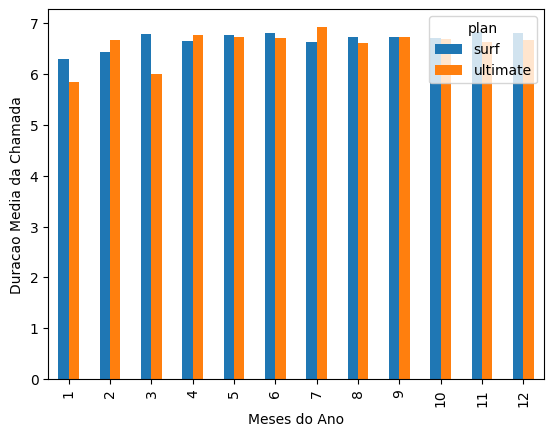

In [74]:
# Average call duration per plan and month (bar chart)
agg_data["duracao_media"] = agg_data["min_mes"] / agg_data["num_chamadas"]
ch_plan = agg_data.groupby(["plan","mes"])["duracao_media"].mean().reset_index()
table = ch_plan.pivot(index = "mes", columns = "plan", values = "duracao_media")
table = table.reset_index()
table.plot(x = "mes",
           y = ["surf","ultimate"],
           kind = "bar",
           xlabel= "Meses do Ano",
           ylabel = "Duracao Media da Chamada")


plt.show()

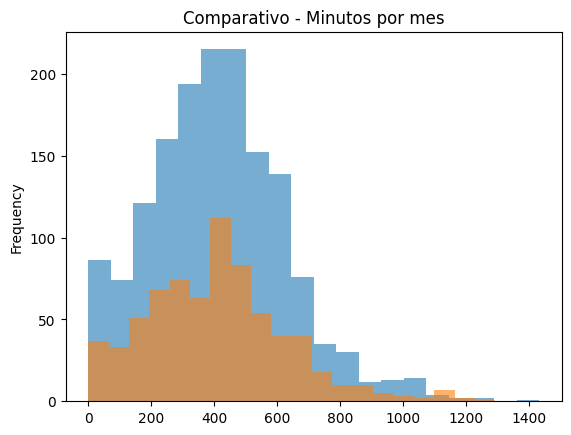

In [84]:
# Distribution of monthly minutes per plan (histogram)
surf_min = agg_data[agg_data["plan"] == "surf"]["min_mes"]
ultimate_min = agg_data[agg_data["plan"] == "ultimate"]["min_mes"]

surf_min.plot(title="Comparativo - Minutos por mes",
              kind="hist",
              bins=20,
              alpha=0.6,
              label="Plano Surf")

ultimate_min.plot(kind="hist",
                  bins=20,
                  alpha=0.6,
                  label="Plano Ultimate")

plt.show()

The mean and variance of monthly call minutes are compared to assess whether users of each plan behave differently.

In [109]:
# Mean and variance of monthly call minutes (Surf, Ultimate)
media_surf = surf_min.mean()
media_ultimate = ultimate_min.mean()
var_surf = surf_min.var(ddof=1)
var_ultimate = ultimate_min.var(ddof=1)

print(media_surf)
print(media_ultimate)
print(var_surf)
print(var_ultimate)


412.0978899676375
410.18095371669006
47001.25423077804
50510.63170498802


<Axes: xlabel='plano', ylabel='min_mes'>

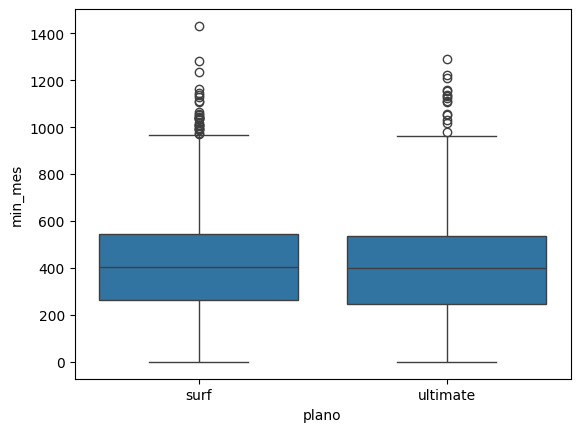

In [ ]:
# Box plot of monthly call minutes per plan
df_box = pd.DataFrame({
    "min_mes": pd.concat([surf_min, ultimate_min], ignore_index=True),
    "plano": ["surf"] * len(surf_min) + ["ultimate"] * len(ultimate_min)
})

sns.boxplot(x="plano", y="min_mes", data=df_box)

**Findings — calls:** monthly call usage is very similar across the two plans (mean of about 412 minutes for Surf vs. 410 for Ultimate; variance of about 47,001 vs. 50,511). The large minute allowance of the Ultimate plan therefore does not appear necessary for a typical customer: usage is similar to Surf, but Ultimate costs $50 more per month, which makes Surf, even with occasional overage charges, the more economical option for the average user.

### Messages

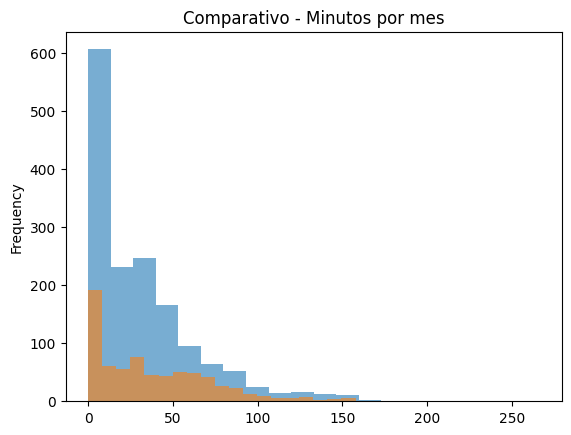

In [113]:
# Distribution of monthly messages per plan (histogram)

surf_msg = agg_data[agg_data["plan"] == "surf"]["n_messages"]
ultimate_msg = agg_data[agg_data["plan"] == "ultimate"]["n_messages"]
surf_msg.plot(title="Comparativo - Minutos por mes",
              kind="hist",
              bins=20,
              alpha=0.6,
              label="Plano Surf")

ultimate_msg.plot(kind="hist",
                  bins=20,
                  alpha=0.6,
                  label="Plano Ultimate")

plt.show()

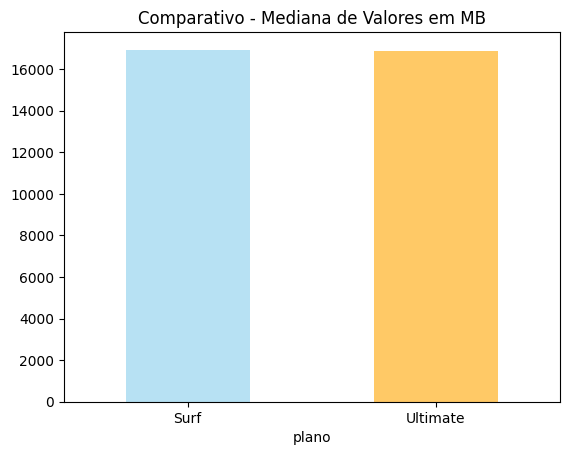

In [137]:
# Median monthly data usage (MB) per plan
mb_surf = agg_data[agg_data["plan"] == "surf"]["mb_mes"]
mb_ultimate = agg_data[agg_data["plan"] == "ultimate"]["mb_mes"]

mb_mean_surf = mb_surf.median()
mb_mean_ultimate = mb_ultimate.median()

values = pd.DataFrame({"plano":["Surf", "Ultimate"],
                       "mediana":[mb_mean_surf, mb_mean_ultimate]})

values.plot(title="Comparativo - Mediana de Valores em MB",
            x="plano",
            y="mediana",
            kind="bar",
            legend=False,
            rot=0,
            color=["skyblue","orange"],
            alpha=0.6)

plt.show()


**Findings — median data usage:** internet usage is very similar between the two plans. The median monthly usage differs by only about 1 GB, and the mean does not change much either, which suggests that Surf remains advantageous even when customers pay for additional data.

### Internet

<Axes: xlabel='plano', ylabel='mb_mes'>

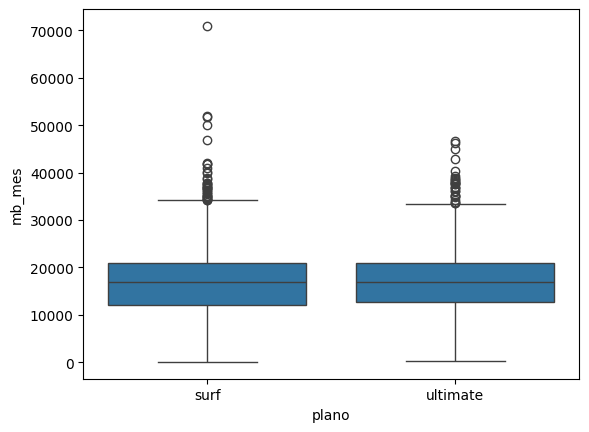

In [138]:
df_box = pd.DataFrame({
    "mb_mes": pd.concat([mb_surf, mb_ultimate], ignore_index=True),
    "plano": ["surf"] * len(mb_surf) + ["ultimate"] * len(mb_ultimate)
})

sns.boxplot(x="plano", y="mb_mes", data=df_box)

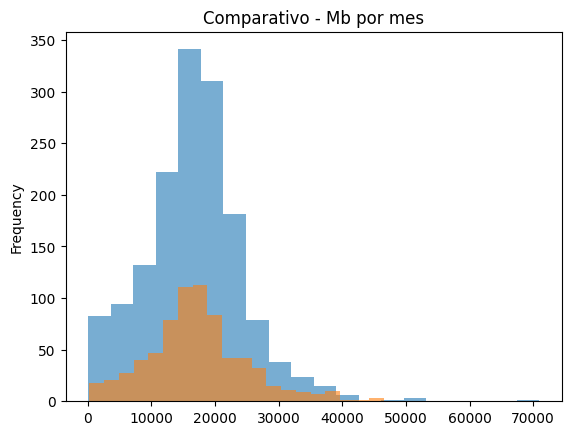

In [139]:
mb_surf.plot(title="Comparativo - Mb por mes",
              kind="hist",
              bins=20,
              alpha=0.6,
              label="Plano Surf")

mb_ultimate.plot(kind="hist",
                  bins=20,
                  alpha=0.6,
                  label="Plano Ultimate")

plt.show()

**Findings — data usage distribution:** Surf users consume more data. This reinforces that Surf is the more cost-effective plan: most users consume roughly 15–20 GB per month, and given the plan prices and overage fees, Surf remains the more affordable option.

## Revenue

Revenue is described per plan in the same way as user behavior: total revenue, its distribution across user-months, and a box plot.

<Axes: title={'center': 'Comparativo - Receita dos Planos'}, xlabel='plano'>

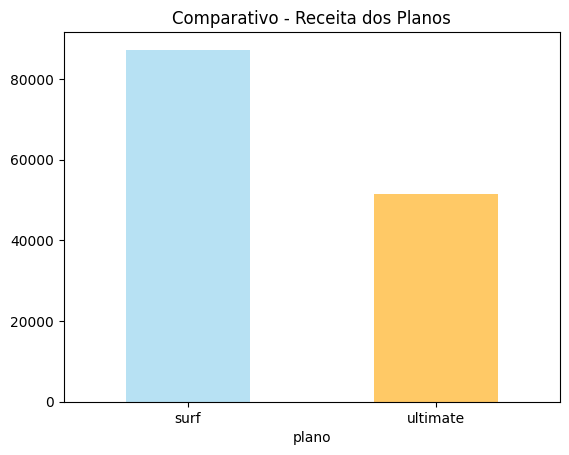

In [161]:
receita_surf = agg_data[agg_data["plan"] == "surf"]["receita_mensal"]
receita_ultimate = agg_data[agg_data["plan"] == "ultimate"]["receita_mensal"]
receita_surf = receita_surf.dropna()
receita_ultimate = receita_ultimate.dropna()

receita_sum_surf = receita_surf.sum()
receita_sum_ultimate = receita_ultimate.sum()

df = pd.DataFrame({"plano":["surf","ultimate"],
                   "valor": [receita_sum_surf, receita_sum_ultimate]})

df.plot(title="Comparativo - Receita dos Planos",
            x="plano",
            y="valor",
            kind="bar",
            legend=False,
            rot=0,
            color=["skyblue","orange"],
            alpha=0.6)

<Axes: xlabel='plano', ylabel='receita'>

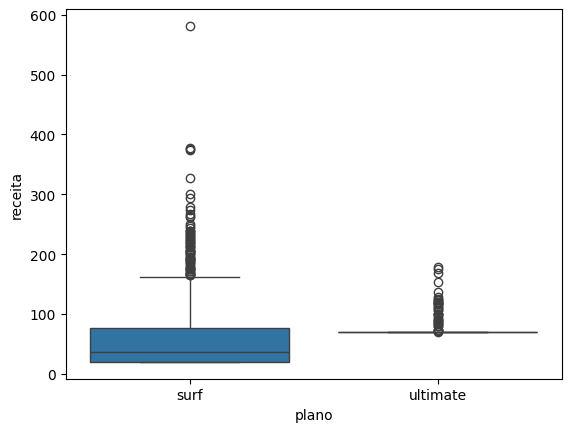

In [162]:
df_box = pd.DataFrame({
    "receita": pd.concat([receita_surf, receita_ultimate], ignore_index=True),
    "plano": ["surf"] * len(receita_surf) + ["ultimate"] * len(receita_ultimate)
})

sns.boxplot(x="plano", y="receita", data=df_box)

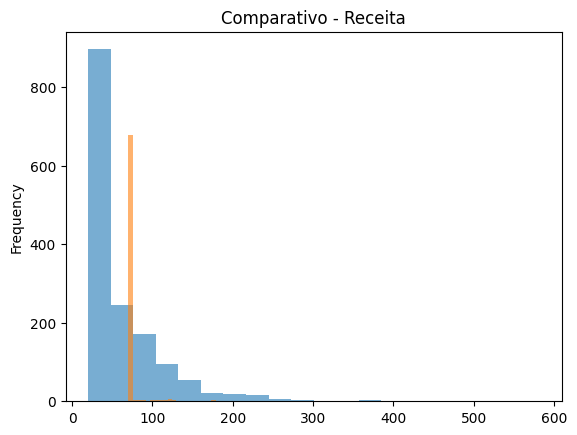

In [163]:
receita_surf.plot(title="Comparativo - Receita",
                  kind="hist",
                  bins=20,
                  alpha=0.6,
                  label="Plano Surf")

receita_ultimate.plot(kind="hist",
                      bins=20,
                      alpha=0.6,
                      label="Plano Ultimate")

plt.show()

**Findings — revenue:** total revenue (the sum over all user-months) from the Surf plan is considerably higher than from Ultimate. Customers appear to favor Surf even though it has lower allowances for minutes, data and messages.

## Hypothesis Testing

### Hypothesis 1: average revenue differs between Surf and Ultimate users

- **H₀:** the mean monthly revenue of Surf users equals that of Ultimate users.
- **H₁:** the mean monthly revenue of Surf users differs from that of Ultimate users.
- **Test:** two-sample t-test (`scipy.stats.ttest_ind`) on monthly revenue per user.
- **Significance level:** α = 0.05.

In [164]:
# Hypothesis test: Surf vs. Ultimate monthly revenue
alpha = 0.05

results = st.ttest_ind(receita_surf, receita_ultimate) # run the test

print('valor-p: ', results.pvalue) # extract the p-value

if results.pvalue < alpha: # compare the p-value with the threshold
    print("Rejeitamos a hipótese nula")
else:
    print("Não podemos rejeitar a hipótese nula")

valor-p:  2.9117600157679376e-14
Rejeitamos a hipótese nula


**Result:** p-value ≈ 2.9 × 10⁻¹⁴ < 0.05, so the null hypothesis is rejected: the mean monthly revenue differs between Surf and Ultimate users.

### Hypothesis 2: average revenue in the NY-NJ area differs from other regions

- **H₀:** the mean monthly revenue of users in the NY-NJ area equals that of users in other regions.
- **H₁:** the mean monthly revenue of users in the NY-NJ area differs from that of users in other regions.
- **Test:** two-sample t-test (`scipy.stats.ttest_ind`). Users are assigned to the NY-NJ group when their `city` contains "NY-NJ".
- **Significance level:** α = 0.05.

In [169]:
receita_users = agg_data.merge(df_users[["user_id","city"]], on=["user_id"],how="left")

mask_nynj = receita_users['city'].str.contains('NY-NJ', na=False)

receita_nynj = receita_users.loc[mask_nynj, 'receita_mensal']
receita_outras = receita_users.loc[~mask_nynj, 'receita_mensal']

receita_nynj = receita_nynj.dropna()
receita_outras = receita_outras.dropna()

alpha = 0.05

results = st.ttest_ind(receita_nynj, receita_outras) # run the test

print('valor-p: ', results.pvalue) # extract the p-value

if results.pvalue < alpha: # compare the p-value with the threshold
    print("Rejeitamos a hipótese nula")
else:
    print("Não podemos rejeitar a hipótese nula")


valor-p:  0.006365452186404033
Rejeitamos a hipótese nula


**Result:** p-value ≈ 0.0064 < 0.05, so the null hypothesis is rejected: the mean monthly revenue of NY-NJ users differs from that of users in other regions.

## Conclusions

- Usage patterns (call minutes and data consumption) are similar for Surf and Ultimate users, even though Ultimate offers much larger allowances at a $50 higher monthly fee.
- Surf shows higher adoption in the sample and generates considerably more total revenue. Despite its lower limits, Surf is the more affordable and practical option for the average user, which suggests that Ultimate's pricing could be revisited to increase adoption.
- The mean monthly revenue differs significantly between the two plans (p ≈ 2.9 × 10⁻¹⁴).
- The mean monthly revenue of users in the New York–New Jersey area differs significantly from that of users in other regions (p ≈ 0.0064).